## Experiment 3: Data Cleaning and Preparation

**Aim:** Data Cleaning and Preparation.

**Objective:** To perform data cleaning and preparation on the Telecom Customer Churn dataset to gain insights into the factors that contribute to customer churn.

In [1]:
# A52 Dipanshu Ambilkar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Step 1: Load the Telecom Customer Churn dataset using pandas
df = pd.read_csv("churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (300, 8)


,customer_id,gender,age,tenure,monthly_charges,total_charges,contract,churn
0,1,Male,51,21,117.92,6825.09,Two year,No
1,2,FEMALE,56,28,28.16,6095.94,One year,Yes
2,3,Female,25,32,55.84,3074.01,Two year,No
3,4,Male,50,10,108.77,4773.68,Month-to-month,Yes
4,5,male,67,21,82.40,2290.87,Two year,No


In [3]:
# Step 2: Explore the structure and content of the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_id      300 non-null    int64  
 1   gender           300 non-null    str    
 2   age              300 non-null    int64  
 3   tenure           300 non-null    int64  
 4   monthly_charges  300 non-null    float64
 5   total_charges    300 non-null    float64
 6   contract         300 non-null    str    
 7   churn            300 non-null    str    
dtypes: float64(2), int64(3), str(3)
memory usage: 18.9 KB


In [4]:
# Step 3: Check missing values using isnull()
print("Missing values in each column:")
print(df.isnull().sum())
print()
print("Total missing values:", df.isnull().sum().sum())

Missing values in each column:
customer_id        0
gender             0
age                0
tenure             0
monthly_charges    0
total_charges      0
contract           0
churn              0
dtype: int64

Total missing values: 0


In [5]:
# Step 4: Check and remove duplicate records
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (300, 8)


In [6]:
# Step 5: Check inconsistent data - unique values of categorical columns
print("Unique gender values:", df["gender"].unique())
print("Unique contract values:", df["contract"].unique())
print("Unique churn values:", df["churn"].unique())

Unique gender values: <StringArray>
['Male', 'FEMALE', 'Female', 'male ']
Length: 4, dtype: str
Unique contract values: <StringArray>
['Two year', 'One year', 'Month-to-month']
Length: 3, dtype: str
Unique churn values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [7]:
# Standardize the gender column: remove spaces and fix the case
df["gender"] = df["gender"].str.strip().str.capitalize()
print("Gender values after standardization:")
print(df["gender"].value_counts())

Gender values after standardization:
gender
Female    155
Male      145
Name: count, dtype: int64


In [8]:
# Handle missing values if any are present (fill numeric with median)
for col in ["age", "tenure", "monthly_charges", "total_charges"]:
    df[col] = df[col].fillna(df[col].median())
print("Missing values now:", df.isnull().sum().sum())

Missing values now: 0


In [9]:
# Step 6: Check outliers in monthly_charges using the IQR method
q1 = df["monthly_charges"].quantile(0.25)
q3 = df["monthly_charges"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = df[(df["monthly_charges"] < lower) | (df["monthly_charges"] > upper)]
print("Lower limit:", round(lower, 2), "| Upper limit:", round(upper, 2))
print("Outlier rows in monthly_charges:", len(outliers))

Lower limit: -30.54 | Upper limit: 165.68
Outlier rows in monthly_charges: 0


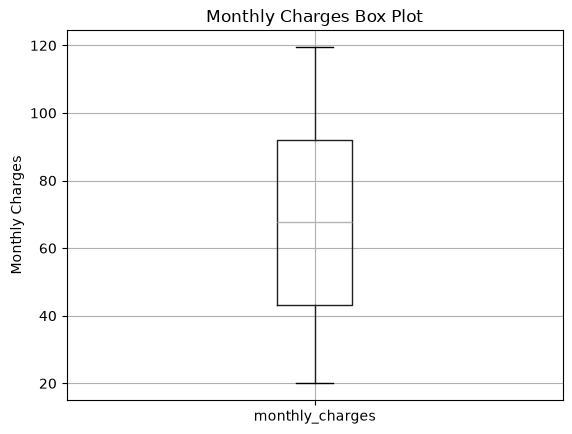

In [10]:
# Box plot to see outliers in monthly_charges visually
df.boxplot(column="monthly_charges")
plt.title("Monthly Charges Box Plot")
plt.ylabel("Monthly Charges")
plt.show()

In [11]:
# Step 7: Feature engineering - create new features useful for churn analysis
df["avg_spend_per_month"] = df["total_charges"] / df["tenure"]
df["tenure_group"] = pd.cut(df["tenure"], bins=[0, 12, 36, 72], labels=["New", "Mid-term", "Long-term"])
df["churn_label"] = df["churn"].map({"No": 0, "Yes": 1})
df.head()

,customer_id,gender,age,tenure,monthly_charges,total_charges,contract,churn,avg_spend_per_month,tenure_group,churn_label
0,1,Male,51,21,117.92,6825.09,Two year,No,325.004286,Mid-term,0
1,2,Female,56,28,28.16,6095.94,One year,Yes,217.712143,Mid-term,1
2,3,Female,25,32,55.84,3074.01,Two year,No,96.062813,Mid-term,0
3,4,Male,50,10,108.77,4773.68,Month-to-month,Yes,477.368000,New,1
4,5,Male,67,21,82.40,2290.87,Two year,No,109.089048,Mid-term,0


In [12]:
# Validate the cleaned data (QA check)
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Gender values:", df["gender"].unique())
print(df.dtypes)

Shape: (300, 11)
Missing values: 0
Duplicate rows: 0
Gender values: <StringArray>
['Male', 'Female']
Length: 2, dtype: str
customer_id               int64
gender                      str
age                       int64
tenure                    int64
monthly_charges         float64
total_charges           float64
contract                    str
churn                       str
avg_spend_per_month     float64
tenure_group           category
churn_label               int64
dtype: object


In [13]:
# Save the cleaned and prepared data to a new CSV file
df.to_csv("churn_cleaned.csv", index=False)
print("Cleaned data saved to churn_cleaned.csv")
saved = pd.read_csv("churn_cleaned.csv")
print("Saved file shape:", saved.shape)
saved.head()

Cleaned data saved to churn_cleaned.csv
Saved file shape: (300, 11)


,customer_id,gender,age,tenure,monthly_charges,total_charges,contract,churn,avg_spend_per_month,tenure_group,churn_label
0,1,Male,51,21,117.92,6825.09,Two year,No,325.004286,Mid-term,0
1,2,Female,56,28,28.16,6095.94,One year,Yes,217.712143,Mid-term,1
2,3,Female,25,32,55.84,3074.01,Two year,No,96.062813,Mid-term,0
3,4,Male,50,10,108.77,4773.68,Month-to-month,Yes,477.368000,New,1
4,5,Male,67,21,82.40,2290.87,Two year,No,109.089048,Mid-term,0


**Conclusion:** In this way we have explored the functions of the Python library for Data Cleaning and Preparation techniques and how to handle missing values on the Telecom Customer Churn dataset. The cleaned and prepared data is saved in churn_cleaned.csv.